In [3]:
# https://medium.com/@maryamuzakariya/project-predict-stock-prices-using-random-forest-regression-model-in-python-fbe4edf01664
import yfinance as yf
import datetime as dt
import pandas as pd
import numpy as np
from numpy import arange
import matplotlib.pyplot as plt
from pandas import read_csv
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV

In [4]:
apple = yf.download(tickers="GOOGL", period="60d", interval="15m")
apple

[*********************100%***********************]  1 of 1 completed


,Open,High,Low,Close,Adj Close,Volume
Datetime,,,,,,
2023-05-03 09:30:00,105.529999,106.029999,104.959999,105.980003,105.980003,1552532
2023-05-03 09:45:00,106.000000,106.250000,105.695000,106.050003,106.050003,976160
2023-05-03 10:00:00,106.059998,106.160004,105.760002,105.989998,105.989998,796791
2023-05-03 10:15:00,105.989998,106.030296,105.610001,105.684998,105.684998,671715
2023-05-03 10:30:00,105.680000,105.870003,105.550003,105.735001,105.735001,572653
...,...,...,...,...,...,...
2023-07-28 14:45:00,132.755005,132.985001,132.690002,132.929993,132.929993,758428
2023-07-28 15:00:00,132.934998,133.089996,132.789993,132.880005,132.880005,893315
2023-07-28 15:15:00,132.889999,132.919998,132.539993,132.595001,132.595001,882623


In [5]:
apple["Target"] = (apple["Open"] < apple["Close"]).astype(int)
apple_df = pd.DataFrame(apple)
apple_df.to_csv("apple_data.csv")

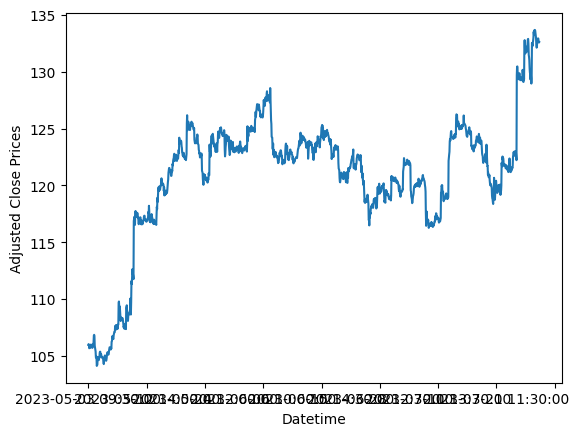

In [6]:
read_df = pd.read_csv("apple_data.csv")
read_df.set_index("Datetime", inplace=True)
read_df['Adj Close'].plot()
plt.ylabel("Adjusted Close Prices")
plt.show()

In [7]:
df = pd.read_csv("apple_data.csv")
df.set_index("Datetime", inplace=True)
df.dropna(inplace=True)

In [8]:
model = RandomForestClassifier(n_estimators=70, min_samples_split=2, random_state=1)

lenn = len(df)
rows = int(df.shape[0]*0.67)
print(lenn)
print(rows)
train = apple.iloc[:- 1 * rows]
test = apple.iloc[-1 * (lenn-rows):]

predictors = ["Close", "Volume", "Open", "High", "Low"]
model.fit(train[predictors], train["Target"])

1548
1037


RandomForestClassifier(n_estimators=70, random_state=1)

In [9]:
from sklearn.metrics import precision_score

preds = model.predict(test[predictors])
preds

array([0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0,

In [10]:
preds = pd.Series(preds, index=test.index)
preds

Datetime
2023-06-29 15:15:00    0
2023-06-29 15:30:00    0
2023-06-29 15:45:00    0
2023-06-30 09:30:00    1
2023-06-30 09:45:00    0
                      ..
2023-07-28 14:45:00    1
2023-07-28 15:00:00    1
2023-07-28 15:15:00    1
2023-07-28 15:30:00    1
2023-07-28 15:45:00    1
Length: 511, dtype: int32

In [11]:
precision_score(test["Target"], preds)

0.6054421768707483

In [12]:
combined = pd.concat([test["Target"], preds], axis=1)

In [13]:
combined

,Target,0
Datetime,,
2023-06-29 15:15:00,0,0
2023-06-29 15:30:00,0,0
2023-06-29 15:45:00,1,0
2023-06-30 09:30:00,1,1
2023-06-30 09:45:00,0,0
...,...,...
2023-07-28 14:45:00,1,1
2023-07-28 15:00:00,0,1
2023-07-28 15:15:00,0,1


In [14]:
def predict(train, test, predictors, model): 
    model.fit(train[predictors], train["Target"])
    preds = model.predict(test[predictors])
    preds = pd.Series(preds, index=test.index, name="Predictions")
    combined = pd.concat([test["Target"], preds], axis=1)
    return combined

def backtest(data, model, predictors, start=1, step=50):
    all_predictions = []
    
    for i in range(start, data.shape[0], step):
        train = data.iloc[0:i].copy()
        test = data.iloc[i:(i+step)].copy()
        predictions = predict(train, test, predictors, model)
        all_predictions.append(predictions)
        
    return pd.concat(all_predictions)

In [15]:
predictions=backtest(apple, model, predictors)

In [16]:
predictions["Predictions"].value_counts()

1    791
0    756
Name: Predictions, dtype: int64

In [17]:
precision_score(predictions["Target"], predictions["Predictions"])

0.6965865992414665

In [18]:
predictions

,Target,Predictions
Datetime,,
2023-05-03 09:45:00,1,1
2023-05-03 10:00:00,0,1
2023-05-03 10:15:00,0,1
2023-05-03 10:30:00,1,1
2023-05-03 10:45:00,1,1
...,...,...
2023-07-28 14:45:00,1,0
2023-07-28 15:00:00,0,0
2023-07-28 15:15:00,0,0


In [19]:
import pickle

In [20]:
# Save the trained model as a pickle string.
saved_model = pickle.dumps(model)